In [34]:
!pip install pandas


[notice] A new release of pip is available: 24.2 -> 24.3.1
[notice] To update, run: python3 -m pip install --upgrade pip


In [35]:
import pandas as pd
import numpy as np 
from sklearn import svm
import matplotlib.pyplot as plt

<Axes: xlabel='x1', ylabel='x2'>

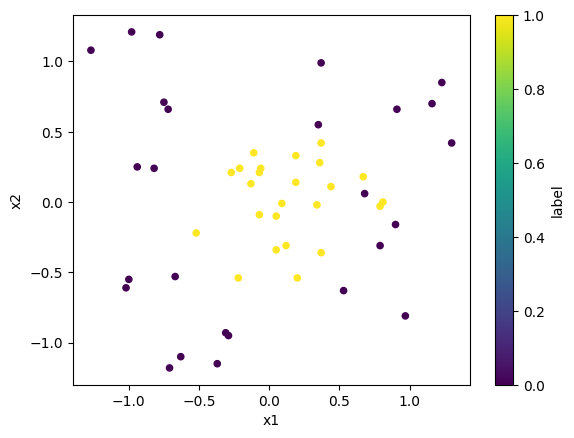

In [36]:
# Assuming 'f' is the file path or a data source
f = './training.csv'  # Replace with your actual file path
f2 = './test.csv'
train = pd.read_csv(f)
test = pd.read_csv(f2)
# Display the DataFrame
train.plot(kind='scatter', x='x1', y='x2', c='label', colormap='viridis')

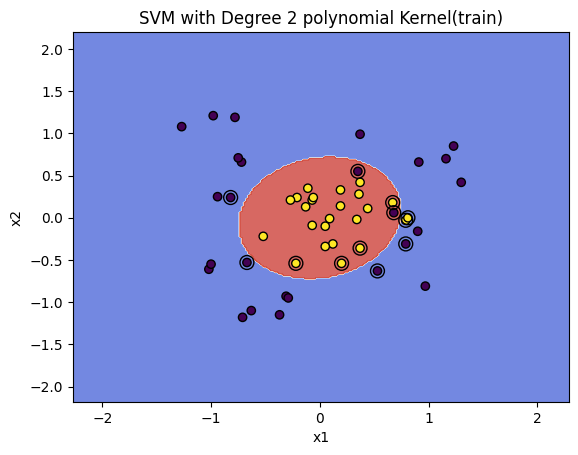

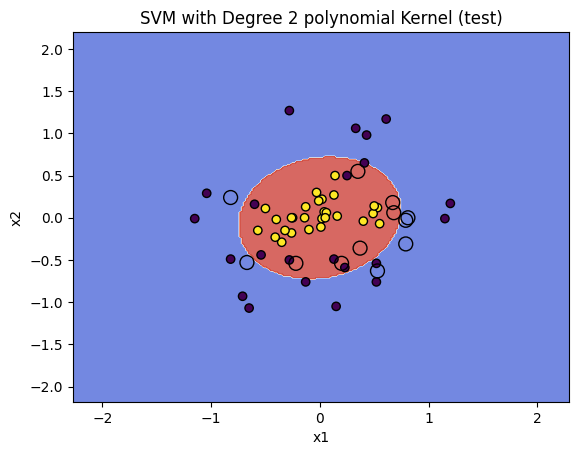

accuracy of rbf kernel is 0.88


In [37]:
x = list(zip(train["x1"],train["x2"]))
y = list(train["label"])

poly = svm.SVC(kernel='poly', degree=2, C=8.0)
d = poly.fit(x, y)
alphas = np.abs(d.dual_coef_)
support_vectors = d.support_vectors_
bias = d.intercept_
b = bias
# Create a mesh grid
h = .02  # step size in the mesh
x_min, x_max = min(train["x1"]) - 1, max(train["x1"]) + 1
y_min, y_max = min(train["x2"]) - 1, max(train["x2"]) + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

# Predict the class for each point in   the mesh grid
Z = poly.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot the decision boundary and support vectors
plt.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.8)
plt.scatter(train["x1"], train["x2"], c=train["label"], cmap='viridis', edgecolors='k')
plt.scatter(poly.support_vectors_[:, 0], poly.support_vectors_[:, 1], s=100, facecolors='none', edgecolors='k')
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('SVM with Degree 2 polynomial Kernel(train)')
plt.show()

# Plot the decision boundary and support vectors
plt.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.8)
plt.scatter(test["x1"], test["x2"], c=test["label"], cmap='viridis', edgecolors='k')
plt.scatter(poly.support_vectors_[:, 0], poly.support_vectors_[:, 1], s=100, facecolors='none', edgecolors='k')
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('SVM with Degree 2 polynomial Kernel (test)')
plt.show()

## testing 
test_points = list(zip(test["x1"],test["x2"]))
test_labels = np.array(list(test["label"]))
test_sets = zip(test_points,test_labels)
predicted_labels = poly.predict(test_points)
predicted_labels.shape
test_labels.shape
count = 0 
for i in range(50):
    if(predicted_labels[i]==test_labels[i]):
      count = count + 1 
print("accuracy of rbf kernel is",count/50)

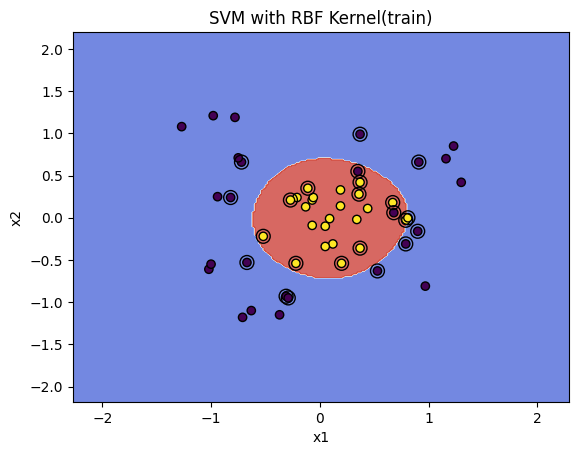

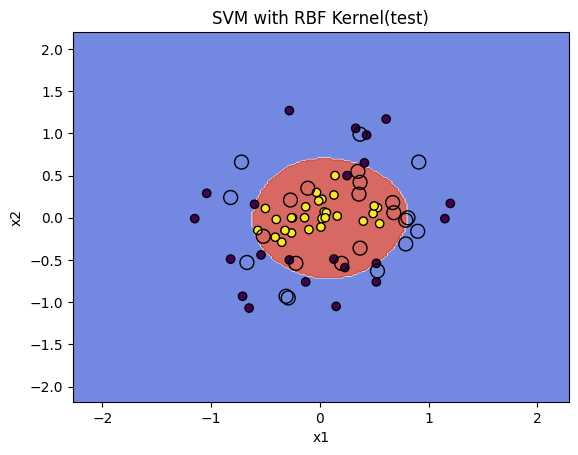

accuracy of rbf kernel is 0.92


In [ ]:
x = list(zip(train["x1"],train["x2"]))
y = list(train["label"])

rbf = svm.SVC(kernel='rbf')
d = rbf.fit(x, y)
alphas = np.abs(d.dual_coef_)
support_vectors = d.support_vectors_
bias = d.intercept_
b = bias
# Create a mesh grid
h = .02  # step size in the mesh-
x_min, x_max = min(train["x1"]) - 1, max(train["x1"]) + 1
y_min, y_max = min(train["x2"]) - 1, max(train["x2"]) + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

# Predict the class for each point in   the mesh grid
Z = rbf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot the decision boundary and support vectors
plt.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.8)
plt.scatter(train["x1"], train["x2"], c=train["label"], cmap='viridis', edgecolors='k')
plt.scatter(rbf.support_vectors_[:, 0], rbf.support_vectors_[:, 1], s=100, facecolors='none', edgecolors='k')
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('SVM with RBF Kernel(train)')
plt.show()

plt.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.8)
plt.scatter(test["x1"], test["x2"], c=test["label"], cmap='viridis', edgecolors='k')
plt.scatter(rbf.support_vectors_[:, 0], rbf.support_vectors_[:, 1], s=100, facecolors='none', edgecolors='k')
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('SVM with RBF Kernel(test)')
plt.show()

## testing 
test_points = list(zip(test["x1"],test["x2"]))
test_labels = np.array(list(test["label"]))
test_sets = zip(test_points,test_labels)
predicted_labels = rbf.predict(test_points)
predicted_labels.shape
test_labels.shape
count = 0 
for i in range(50):
    if(predicted_labels[i]==test_labels[i]):
      count = count + 1 
print("accuracy of rbf kernel is",count/50)